In [1]:
import sys; sys.path.append("..")
from config import YEARS
from src.data_loader import build_unified_dataset, log_null_report
import numpy as np

df = build_unified_dataset(YEARS)
por_año = log_null_report(df)
por_año        # tabla de nulos por columna y año, para el EDA

2026-11-10 02:21:49,662 | INFO     | src.data_loader | [2001] archivo encontrado: departamentos-en-venta-2001.csv


2026-11-10 02:21:50,225 | INFO     | src.data_loader | [2001] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:21:50,231 | WARNING  | src.data_loader | [2001] 12911 filas con LAT/LON invertidas, se corrigen


2026-11-10 02:21:50,392 | INFO     | src.data_loader | [2001] estandarizado: (12911, 17) -> (12911, 22)


2026-11-10 02:21:50,442 | INFO     | src.data_loader | [2002] archivo encontrado: departamentos-en-venta-2002.csv


2026-11-10 02:21:50,686 | INFO     | src.data_loader | [2002] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


... (68 outputs left out)

2026-11-10 02:21:54,619 | WARNING  | src.data_loader | [2014] columnas completamente nulas: ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:21:54,623 | WARNING  | src.data_loader | [2015] columnas completamente nulas: ['M2_CUBIERTOS', 'ORIENT']


2026-11-10 02:21:54,626 | WARNING  | src.data_loader | [2016] columnas completamente nulas: ['DORMITORIO', 'PISO', 'ORIENT', 'BAULERA', 'COCHERA', 'LAVADERO', 'TERRAZA']


,CALLE,NUMERO,M2,M2_CUBIERTOS,DOLARES,U_S_M2,AMBIENTES,DORMITORIO,PISO,ANTIGUEDAD,...,BAULERA,COCHERA,BAÑOS,LAVADERO,TERRAZA,BARRIO,COMUNA,DIRECCION_NORMALIZADA,LAT,LON
AÑO,,,,,,,,,,,,,,,,,,,,,
2001,0,0,0,12911,0,0,12815,12911,12911,12028,...,12247,11154,0,9876,4748,0,0,12911,0,0
2002,0,0,0,7363,0,0,7363,7363,7363,6828,...,6917,6335,0,5918,3051,0,0,7363,0,0
2003,0,0,0,13525,0,0,13439,13525,13525,12552,...,12890,11665,11243,10757,5600,0,0,13525,0,0
2004,0,0,0,4808,0,0,4808,4808,4808,2681,...,4599,4448,4808,4808,4364,0,0,4808,0,0
2005,0,0,0,3503,0,0,0,3503,3503,0,...,3174,2955,3503,3503,3478,0,0,3503,0,0
2006,0,0,0,3448,0,0,0,3448,3448,0,...,3149,2972,2346,1793,1419,0,0,3448,0,0
2007,0,5,5,7910,5,5,5,7910,7910,5,...,7528,7220,5,4617,3523,5,5,7910,0,0
2008,0,0,0,7524,0,0,0,7524,7524,4691,...,6733,6448,5253,5660,3626,0,0,7524,0,0
2009,0,0,0,23614,0,0,9100,23614,23614,0,...,22129,21399,15120,20692,19039,0,0,23614,0,0


In [2]:
# 1. Las filas raras de 2012
lat_ok = df["LAT"].between(-34.72, -34.52)
lon_ok = df["LON"].between(-58.54, -58.33)
fuera = df[df["LAT"].notna() & ~(lat_ok & lon_ok)]
print(fuera[["AÑO", "CALLE", "BARRIO", "LAT", "LON"]].head(10))
print(fuera[["LAT", "LON"]].describe())

# 2. Porcentaje de nulos por año (mejor que la tabla de conteos)
print((df.drop(columns="AÑO").isnull().groupby(df["AÑO"]).mean() * 100).round(0))

# 3. Categóricas y numéricas
print(df["BARRIO"].nunique(), df["BARRIO"].unique()[:30])
for c in ["AMBIENTES", "ANTIGUEDAD", "COCHERA", "LAVADERO"]:
    print(df[c].value_counts(dropna=False).head(10), "\n")

# 4. Precio y superficie
print(df[["M2", "DOLARES", "U_S_M2"]].describe())

         AÑO                            CALLE         BARRIO      LAT  \
120502  2012     ACUÑA DE FIGUEROA, FRANCISCO        PALERMO -89.9982   
120503  2012     ACUÑA DE FIGUEROA, FRANCISCO        PALERMO -89.9982   
120504  2012     ACUÑA DE FIGUEROA, FRANCISCO        PALERMO -89.9982   
120505  2012     ACUÑA DE FIGUEROA, FRANCISCO        PALERMO -89.9982   
120506  2012     ACUÑA DE FIGUEROA, FRANCISCO      BALVANERA -89.9982   
123964  2012  FERNANDEZ DE LA CRUZ, F., GRAL.  NUEVA POMPEYA -89.9982   
124084  2012     FRAY JUSTO SANTAMARIA DE ORO        PALERMO -89.9982   
124085  2012     FRAY JUSTO SANTAMARIA DE ORO        PALERMO -89.9982   
124086  2012     FRAY JUSTO SANTAMARIA DE ORO        PALERMO -89.9982   
124087  2012     FRAY JUSTO SANTAMARIA DE ORO        PALERMO -89.9982   

               LON  
120502  137.419509  
120503  137.419509  
120504  137.419509  
120505  137.419509  
120506  137.419509  
123964  137.419509  
124084  137.419509  
124085  137.419509  
124086 

      CALLE  NUMERO   M2  M2_CUBIERTOS  DOLARES  U_S_M2  AMBIENTES  \
AÑO                                                                  
2001    0.0     0.0  0.0         100.0      0.0     0.0       99.0   
2002    0.0     0.0  0.0         100.0      0.0     0.0      100.0   
2003    0.0     0.0  0.0         100.0      0.0     0.0       99.0   
2004    0.0     0.0  0.0         100.0      0.0     0.0      100.0   
2005    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2006    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2007    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2008    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2009    0.0     0.0  0.0         100.0      0.0     0.0       39.0   
2010    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2011    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2012    0.0     0.0  0.0         100.0      0.0     0.0        0.0   
2013    0.0     0.0 

In [3]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from config import YEARS
from src.data_loader import build_unified_dataset
from src.cleaning import clean_dataset
from src.logger_setup import flush_mongo_logs

df_raw = build_unified_dataset(YEARS)

2026-11-10 02:22:10,019 | INFO     | src.data_loader | [2001] archivo encontrado: departamentos-en-venta-2001.csv


2026-11-10 02:22:10,201 | INFO     | src.data_loader | [2001] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:22:10,205 | WARNING  | src.data_loader | [2001] 12911 filas con LAT/LON invertidas, se corrigen


2026-11-10 02:22:10,349 | INFO     | src.data_loader | [2001] estandarizado: (12911, 17) -> (12911, 22)


2026-11-10 02:22:10,352 | INFO     | src.data_loader | [2002] archivo encontrado: departamentos-en-venta-2002.csv


2026-11-10 02:22:10,472 | INFO     | src.data_loader | [2002] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


... (50 outputs left out)

2026-11-10 02:22:13,544 | INFO     | src.data_loader | [2016] estandarizado: (7564, 29) -> (7564, 22)


2026-11-10 02:22:13,698 | INFO     | src.data_loader | Dataset unificado: 178492 filas, 22 columnas


2026-11-10 02:22:13,710 | INFO     | src.data_loader | Coordenadas fuera de CABA en total: 150


2026-11-10 02:22:13,712 | WARNING  | src.data_loader | [2012] 150 filas con coordenadas fuera de CABA


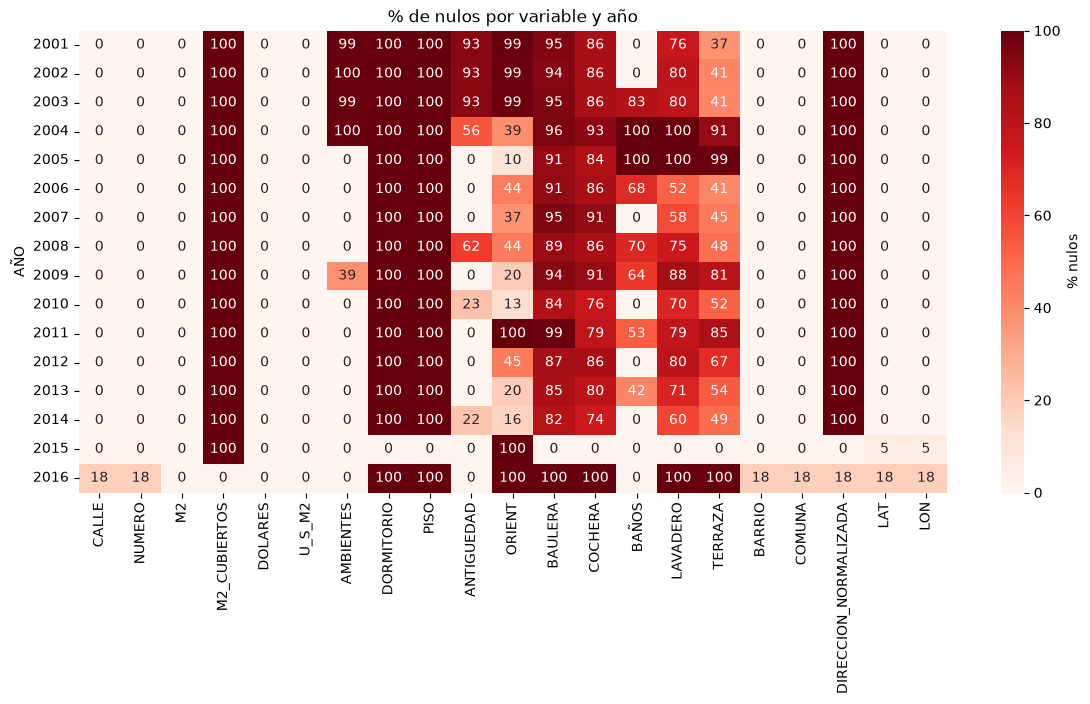

In [4]:
nulos = df_raw.drop(columns="AÑO").isnull().groupby(df_raw["AÑO"]).mean() * 100
plt.figure(figsize=(14, 6))
sns.heatmap(nulos, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% nulos"})
plt.title("% de nulos por variable y año"); plt.show()

In [5]:
# ¿Qué significa AMBIENTES == 0? Comparar superficie mediana
print(df_raw.groupby(df_raw["AMBIENTES"] == 0)["M2"].median())
print(df_raw.groupby("AMBIENTES")["M2"].median().head(8))

print(df_raw["ORIENT"].value_counts(dropna=False).head(15))
print(sorted(df_raw["BARRIO"].dropna().unique()))
print(df_raw["BAÑOS"].value_counts(dropna=False).head(10))
print(df_raw.groupby("AÑO")["U_S_M2"].describe().round(0))

AMBIENTES
False    66.0
True     60.0
Name: M2, dtype: float64
AMBIENTES
0.0     60.0
1.0     36.0
2.0     46.0
3.0     70.0
4.0    111.0
5.0    190.0
6.0    198.5
7.0    219.0
Name: M2, dtype: float64
ORIENT
NaN                      96346
FRENTE                   49332
CONTRAFRENTE             24828
LATERAL                   4569
INTERNO                   1836
frente                     767
0                          302
contrafrente               227
FRENTE Y CONTRAFRENTE      111
SI                          73
lateral                     53
interno                     21
DOBLE FRENTE                 6
FRENTE Y CONTRA              3
FONDO                        2
Name: count, dtype: int64
['AGRONOMIA', 'ALMAGRO', 'BALVANERA', 'BARRACAS', 'BELGRANO', 'BOCA', 'BOEDO', 'CABALLITO', 'CHACARITA', 'COGHLAN', 'COLEGIALES', 'CONSTITUCION', 'FLORES', 'FLORESTA', 'LINIERS', 'MATADEROS', 'MONSERRAT', 'MONTE CASTRO', 'MONTSERRAT', 'NUEVA POMPEYA', 'NUNEZ', 'NUÑEZ', 'PALERMO', 'PARQUE AVELLANED',

In [6]:
s = df_raw["U_S_M2"].astype("string").str.strip()
num = pd.to_numeric(s, errors="coerce")
raros = s[num.isna() & s.notna()]
print(len(raros), "valores no numéricos de", len(s))
print(raros.value_counts().head(15))
print(df_raw.loc[raros.index, "AÑO"].value_counts().sort_index())

9094 valores no numéricos de 178492


U_S_M2
1666,7    74
2142,9    53
2333,3    39
1857,1    39
2166,7    34
1833,3    33
2083,3    32
1785,7    28
1923,1    27
2222,2    26
1571,4    26
1777,8    24
1944,4    24
1818,2    21
2666,7    21
Name: count, dtype: int64[pyarrow]
AÑO
2015    9094
Name: count, dtype: int64


In [7]:
clean_dataset(df_raw)

2026-11-10 02:22:17,871 | INFO     | src.cleaning | === Inicio de limpieza: 178492 filas, 22 columnas ===


2026-11-10 02:22:17,973 | INFO     | src.cleaning | Se descartan columnas casi vacías: ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:22:18,538 | INFO     | src.cleaning | Duplicados exactos: 178492 -> 175513 filas (2979 eliminadas)


2026-11-10 02:22:19,458 | INFO     | src.cleaning | Sin M2 o precio: 175513 -> 175508 filas (5 eliminadas)


2026-11-10 02:22:19,586 | INFO     | src.cleaning | Outliers de M2/DOLARES: 175508 -> 175179 filas (329 eliminadas)


2026-11-10 02:22:19,615 | WARNING  | src.cleaning | [2002] 8 filas con PRECIO_M2 fuera de rango


... (18 outputs left out)

2026-11-10 02:22:21,126 | INFO     | src.cleaning | BAÑOS: 41027 valores (<=0 o >8) pasan a NaN


2026-11-10 02:22:21,282 | INFO     | src.cleaning | Distribución del target:
SEGMENTO
alto     58046
medio    58036
bajo     58034


2026-11-10 02:22:21,296 | INFO     | src.cleaning | === Fin de limpieza: 174116 filas, 20 columnas ===


,AÑO,CALLE,NUMERO,M2,DOLARES,U_S_M2,AMBIENTES,ANTIGUEDAD,ORIENT,BAULERA,COCHERA,BAÑOS,LAVADERO,TERRAZA,BARRIO,COMUNA,LAT,LON,PRECIO_M2,SEGMENTO
0,2001,11 DE SEPTIEMBRE DE 1888,882.0,105.0,173000.0,1647.6,NaN,0.0,NaN,0.0,1.0,2.0,0.0,0.0,PALERMO,14.0,-34.569951,-58.440246,1647.619048,alto
1,2001,11 DE SEPTIEMBRE DE 1888,1050.0,180.0,169000.0,938.9,NaN,NaN,NaN,0.0,1.0,2.0,0.0,0.0,PALERMO,14.0,-34.568205,-58.442481,938.888889,medio
2,2001,11 DE SEPTIEMBRE DE 1888,1144.0,165.0,185000.0,1121.2,NaN,NaN,NaN,0.0,1.0,2.0,0.0,0.0,PALERMO,14.0,-34.567569,-58.443303,1121.212121,alto
3,2001,11 DE SEPTIEMBRE DE 1888,1846.0,202.0,198000.0,980.2,NaN,NaN,NaN,0.0,1.0,2.0,0.0,0.0,BELGRANO,13.0,-34.561004,-58.449033,980.198020,alto
4,2001,11 DE SEPTIEMBRE DE 1888,2130.0,63.0,50000.0,793.7,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BELGRANO,13.0,-34.558023,-58.451617,793.650794,bajo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174111,2016,TACUARI,1842.0,500.0,85200.0,213.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BARRACAS,NaN,-34.629636,-58.374953,170.400000,bajo
174112,2016,MALABIA,2233.0,130.0,450000.0,4411.0,4.0,NaN,NaN,NaN,NaN,3.0,NaN,NaN,PALERMO,NaN,-34.586707,-58.420745,3461.538462,alto
174113,2016,BAEZ,650.0,45.0,70000.0,1750.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PALERMO,NaN,-34.569868,-58.434968,1555.555556,bajo
174114,2016,"ALVEAR, MARCELO T. DE",1528.0,67.0,227707.0,3398.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,RECOLETA,NaN,-34.597178,-58.388745,3398.611940,alto


In [8]:
df_raw = build_unified_dataset(YEARS)
df_clean = clean_dataset(df_raw)
print(df_clean.dtypes[["M2", "DOLARES", "U_S_M2"]])   # los tres tienen que ser float64

2026-11-10 02:22:21,459 | INFO     | src.data_loader | [2001] archivo encontrado: departamentos-en-venta-2001.csv


2026-11-10 02:22:21,644 | INFO     | src.data_loader | [2001] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:22:21,647 | WARNING  | src.data_loader | [2001] 12911 filas con LAT/LON invertidas, se corrigen


2026-11-10 02:22:21,650 | INFO     | src.data_loader | [2001] estandarizado: (12911, 17) -> (12911, 22)


2026-11-10 02:22:21,652 | INFO     | src.data_loader | [2002] archivo encontrado: departamentos-en-venta-2002.csv


2026-11-10 02:22:21,800 | INFO     | src.data_loader | [2002] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


... (78 outputs left out)

2026-11-10 02:22:28,721 | INFO     | src.cleaning | BAÑOS: 41027 valores (<=0 o >8) pasan a NaN


2026-11-10 02:22:28,878 | INFO     | src.cleaning | Distribución del target:
SEGMENTO
alto     58046
medio    58036
bajo     58034


2026-11-10 02:22:28,937 | INFO     | src.cleaning | === Fin de limpieza: 174116 filas, 20 columnas ===


M2         float64
DOLARES    float64
U_S_M2     float64
dtype: object


In [9]:
d = df_clean.copy()
d["desvio"] = ((d["DOLARES"] / d["M2"] - d["U_S_M2"]).abs() / d["U_S_M2"]) > 0.05
print(d.groupby("AÑO")["desvio"].agg(["sum", "mean"]).round(3))

       sum   mean
AÑO              
2001     0  0.000
2002     0  0.000
2003     0  0.000
2004     0  0.000
2005     0  0.000
2006     0  0.000
2007     0  0.000
2008     1  0.000
2009     8  0.000
2010     0  0.000
2011     1  0.000
2012     1  0.000
2013     0  0.000
2014     4  0.000
2015     0  0.000
2016  2644  0.632


In [10]:
print(df_clean.assign(est=df_clean["ANTIGUEDAD"] == 0).groupby("AÑO")["est"].mean().round(2))
print(df_clean.groupby(df_clean["ANTIGUEDAD"] == 0)["U_S_M2"].median())

AÑO
2001    0.05
2002    0.04
2003    0.03
2004    0.06
2005    0.07
2006    0.11
2007    0.00
2008    0.13
2009    0.22
2010    0.15
2011    0.04
2012    0.06
2013    0.00
2014    0.12
2015    0.00
2016    0.00
Name: est, dtype: float64
ANTIGUEDAD
False    1606.1
True     1729.7
Name: U_S_M2, dtype: float64


In [11]:
def num(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", ".", regex=False), errors="coerce")

r = df_raw[df_raw["AÑO"] == 2016].copy()
for c in ["M2", "M2_CUBIERTOS", "DOLARES", "U_S_M2"]:
    r[c] = num(r[c])

ok_total = ((r["DOLARES"] / r["M2"] - r["U_S_M2"]).abs() / r["U_S_M2"] < 0.05).mean()
ok_cub = ((r["DOLARES"] / r["M2_CUBIERTOS"] - r["U_S_M2"]).abs() / r["U_S_M2"] < 0.05).mean()
print("coincide con M2:", round(ok_total, 2), "| coincide con M2_CUBIERTOS:", round(ok_cub, 2))
print(r[["M2", "M2_CUBIERTOS", "DOLARES", "U_S_M2"]].head(10))

coincide con M2: 0.36 | coincide con M2_CUBIERTOS: 0.96
           M2  M2_CUBIERTOS   DOLARES  U_S_M2
170928   57.0          50.0  170150.0    3403
170929   46.0          46.0  118650.0    2579
170930   61.0          56.0  181470.0    3241
170931  140.0          76.0  320000.0    4211
170932   39.0          33.0   82116.0    2488
170933   39.0          34.0   81921.0    2409
170934   50.0          45.0  103802.0    2307
170935   82.0          58.0  265000.0    4569
170936   38.0          38.0  145000.0    3816
170937   38.0          35.0  147000.0    4200


In [12]:
a = df_raw[["AÑO", "ANTIGUEDAD"]].copy()
txt = a["ANTIGUEDAD"].astype("string").str.strip().str.upper()

def mask(m):
    return m.fillna(False).to_numpy(dtype=bool)

a["tipo"] = np.select(
    [mask(txt == "A ESTRENAR"), mask(txt.isin(["0", "0.0"])), mask(txt.isna() | (txt == ""))],
    ["a_estrenar", "cero", "vacio"], default="otro")
print(pd.crosstab(a["AÑO"], a["tipo"], normalize="index").round(2))

tipo  a_estrenar  cero  otro  vacio
AÑO                                
2001        0.05  0.00  0.02   0.93
2002        0.04  0.00  0.03   0.93
2003        0.03  0.00  0.04   0.93
2004        0.06  0.00  0.39   0.56
2005        0.07  0.22  0.70   0.00
2006        0.11  0.48  0.41   0.00
2007        0.00  0.59  0.40   0.00
2008        0.13  0.00  0.24   0.62
2009        0.22  0.23  0.55   0.00
2010        0.15  0.00  0.62   0.23
2011        0.04  0.62  0.34   0.00
2012        0.06  0.39  0.55   0.00
2013        0.00  0.40  0.60   0.00
2014        0.12  0.00  0.67   0.22
2015        0.00  0.00  0.56   0.44
2016        0.00  0.24  0.76   0.00


In [13]:
from src.db_sql import save_clean_data, load_clean_data

df_clean = clean_dataset(df_raw)
save_clean_data(df_clean)
df_check = load_clean_data()     # comprobación de ida y vuelta
print(df_check.dtypes)
flush_mongo_logs()

2026-11-10 02:22:31,439 | INFO     | src.cleaning | === Inicio de limpieza: 178492 filas, 22 columnas ===


2026-11-10 02:22:31,545 | INFO     | src.cleaning | Se descartan columnas casi vacías: ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']


2026-11-10 02:22:32,013 | INFO     | src.cleaning | Duplicados exactos: 178492 -> 175513 filas (2979 eliminadas)


2026-11-10 02:22:32,908 | INFO     | src.cleaning | Sin M2 o precio: 175513 -> 175508 filas (5 eliminadas)


2026-11-10 02:22:33,053 | INFO     | src.cleaning | Outliers de M2/DOLARES: 175508 -> 175179 filas (329 eliminadas)


2026-11-10 02:22:33,063 | WARNING  | src.cleaning | [2002] 8 filas con PRECIO_M2 fuera de rango


... (20 outputs left out)

2026-11-10 02:22:34,897 | INFO     | src.cleaning | === Fin de limpieza: 174116 filas, 20 columnas ===


2026-11-10 02:22:42,393 | INFO     | src.db_sql | Tabla 'datos_limpios' guardada en deptos.db: 174116 filas


2026-11-10 02:22:44,557 | INFO     | src.db_sql | Tabla 'datos_limpios' leída: 174116 filas, 20 columnas


AÑO             int64
CALLE             str
NUMERO        float64
M2            float64
DOLARES       float64
U_S_M2        float64
AMBIENTES     float64
ANTIGUEDAD    float64
ORIENT            str
BAULERA       float64
COCHERA       float64
BAÑOS         float64
LAVADERO      float64
TERRAZA       float64
BARRIO            str
COMUNA        float64
LAT           float64
LON           float64
PRECIO_M2     float64
SEGMENTO          str
dtype: object
